# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

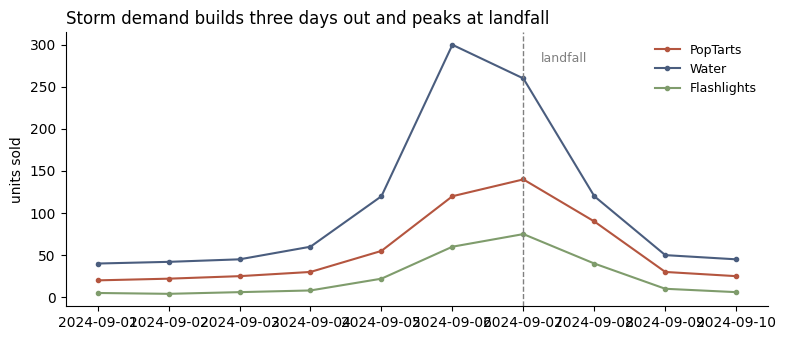

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

In [2]:
import pandas as pd

BASE = 'https://raw.githubusercontent.com/karen-tran08/walmart-hurricane-project/main/data/'
txns = pd.read_csv(BASE + 'transactions_clean.csv', parse_dates=['timestamp'])
stores = pd.read_csv(BASE + 'stores_clean.csv')

print(len(txns), txns.dtypes)   # should be 25,402 rows, timestamp as datetime64

25402 transaction_id            object
store_id                  object
timestamp         datetime64[ns]
sku                       object
product_name              object
category                  object
quantity                   int64
unit_price               float64
dtype: object


In [3]:
print('--- Time Range ---')
print('Min date:', txns['timestamp'].min())
print('Max date:', txns['timestamp'].max())

print('\n--- Top Categories ---')
print(txns['category'].value_counts())

print('\n--- Top Products ---')
print(txns['product_name'].value_counts().head(15))

print('\n--- Number of unique stores ---')
print(txns['store_id'].nunique())

--- Time Range ---
Min date: 2024-09-01 06:01:15
Max date: 2024-09-30 22:57:47

--- Top Categories ---
category
EMERGENCY                1811
Emergency Supplies       1811
emergency                1779
Emergency                1751
Groceries                 854
electronics               854
Electronics               836
Grocery                   831
ELECTRONICS               818
grocery                   808
GROCERY                   800
Entertainment             645
Games & Entertainment     643
entertainment             637
ENTERTAINMENT             602
HOUSEHOLD                 600
Household                 587
household                 583
Household Essentials      570
baby                      543
breakfast                 530
Breakfast                 524
Baby                      520
BABY                      517
BREAKFAST                 509
Baby Products             497
Breakfast Foods           490
Alcohol                   434
ALCOHOL                   426
Alcoholic Beverage

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

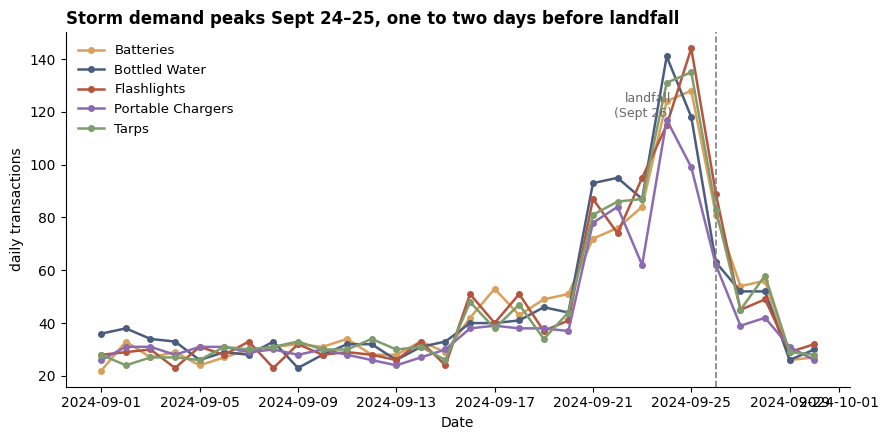

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Standardize product names to group identical products
def standardize_product(name):
    name = str(name).upper().strip()
    if 'WATER' in name:
        return 'Bottled Water'
    elif 'FLASHLIGHT' in name:
        return 'Flashlights'
    elif 'TARP' in name:
        return 'Tarps'
    elif 'BATTERIES' in name:
        return 'Batteries'
    elif 'CHARGER' in name:
        return 'Portable Chargers'
    return 'Other'

txns['standard_product'] = txns['product_name'].apply(standardize_product)
txns['date'] = txns['timestamp'].dt.date

# Aggregate transaction counts (instead of quantities) daily
daily_sales = txns[txns['standard_product'] != 'Other'].groupby(['date', 'standard_product']).size().unstack(fill_value=0)
daily_sales.index = pd.to_datetime(daily_sales.index)

# Rebuilding the chart for Pattern 1
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = {'Bottled Water': '#4a5d7e', 'Flashlights': '#b4553f', 'Tarps': '#7f9c6c', 'Batteries': '#d9a05b', 'Portable Chargers': '#8c6bb1'}

for col in daily_sales.columns:
    ax.plot(daily_sales.index, daily_sales[col], marker='o', ms=4, color=colors.get(col, 'gray'), label=col, lw=1.8)

# Mark the peak / expected landfall (Sept 26)
landfall_est = pd.Timestamp('2024-09-26')
ax.axvline(landfall_est, ls='--', color='gray', lw=1.2)
ax.annotate('landfall\n(Sept 26)', xy=(landfall_est - pd.Timedelta(days=1.8), daily_sales.max().max() * 0.82),
            fontsize=9, color='dimgray', ha='right')

ax.set_title('Storm demand peaks Sept 24–25, one to two days before landfall', loc='left', fontsize=12, fontweight='bold')
ax.set_ylabel('daily transactions')
ax.set_xlabel('Date')
ax.legend(frameon=False, fontsize=9.5, loc='upper left')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

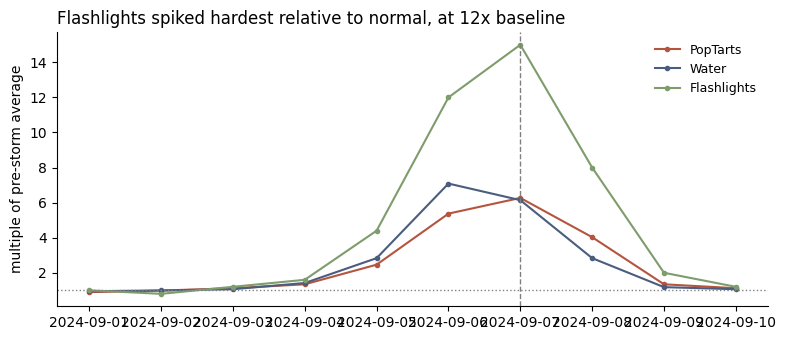

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [5]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

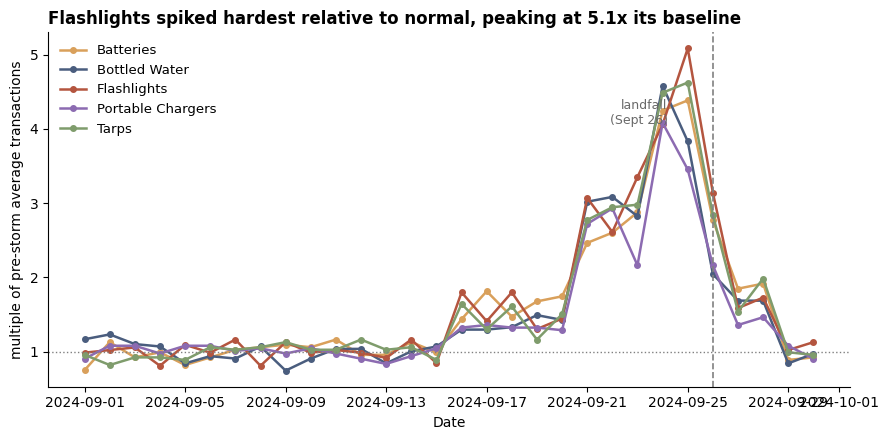

--- Maximum Surge Multipliers (vs Baseline) ---
standard_product
Flashlights          5.1
Tarps                4.6
Bottled Water        4.6
Batteries            4.4
Portable Chargers    4.1
dtype: float64


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Define a pre-storm baseline window (using <= 2024-09-15 to cover exactly 15 days)
baseline_start = '2024-09-01'
baseline_end = '2024-09-15'

# Calculate baseline daily transactions for each cleaned product category
baseline = daily_sales[(daily_sales.index >= baseline_start) & (daily_sales.index <= baseline_end)].mean()

# Compute daily transactions indexed to that baseline
indexed_sales = daily_sales / baseline

# Plot the indexed trends to see the multiples
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = {'Bottled Water': '#4a5d7e', 'Flashlights': '#b4553f', 'Tarps': '#7f9c6c', 'Batteries': '#d9a05b', 'Portable Chargers': '#8c6bb1'}

for col in indexed_sales.columns:
    ax.plot(indexed_sales.index, indexed_sales[col], marker='o', ms=4, color=colors.get(col, 'gray'), label=col, lw=1.8)

# Draw line at 1.0 (representing baseline level)
ax.axhline(1.0, ls=':', color='gray', lw=1)

# Draw expected landfall line
landfall_est = pd.Timestamp('2024-09-26')
ax.axvline(landfall_est, ls='--', color='gray', lw=1.2)
ax.annotate('landfall\n(Sept 26)', xy=(landfall_est - pd.Timedelta(days=1.8), indexed_sales.max().max() * 0.8),
            fontsize=9, color='dimgray', ha='right')

# Find maximum multiplier
max_multipliers = indexed_sales.max().round(1)
top_mover = max_multipliers.idxmax()
top_val = max_multipliers.max()

ax.set_title(f'{top_mover} spiked hardest relative to normal, peaking at {top_val}x its baseline', loc='left', fontsize=12, fontweight='bold')
ax.set_ylabel('multiple of pre-storm average transactions')
ax.set_xlabel('Date')
ax.legend(frameon=False, fontsize=9.5, loc='upper left')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

print("--- Maximum Surge Multipliers (vs Baseline) ---")
print(max_multipliers.sort_values(ascending=False))

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

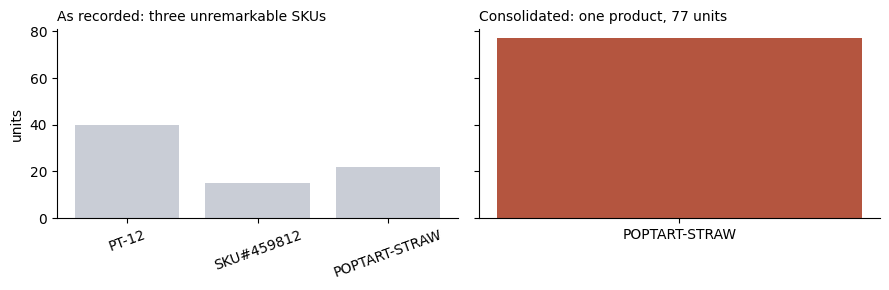

In [7]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

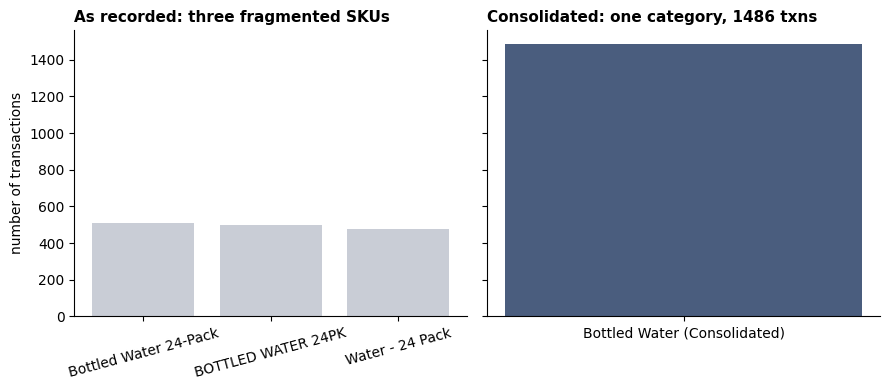

Consolidation gathers 1486 total transactions, which is 2.9x larger than the largest single raw SKU volume!


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Count the transactions of each raw product name that we consolidated into 'Bottled Water'
water_names = ['Bottled Water 24-Pack', 'BOTTLED WATER 24PK', 'Water - 24 Pack']
fragmented_counts = txns[txns['product_name'].isin(water_names)]['product_name'].value_counts()

# Consolidated count is the sum of these
consolidated_total = fragmented_counts.sum()
consolidated_series = pd.Series({'Bottled Water (Consolidated)': consolidated_total})

# Set up side-by-side comparison chart
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

# Left chart: Fragmented
axes[0].bar(fragmented_counts.index, fragmented_counts.values, color='#c9cdd6')
axes[0].set_title('As recorded: three fragmented SKUs', fontsize=11, loc='left', fontweight='bold')
axes[0].set_ylabel('number of transactions')
axes[0].tick_params(axis='x', labelrotation=15)

# Right chart: Consolidated
axes[1].bar(consolidated_series.index, consolidated_series.values, color='#4a5d7e', width=0.4)
axes[1].set_title(f'Consolidated: one category, {consolidated_total} txns', fontsize=11, loc='left', fontweight='bold')

for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

largest_single_sku_val = fragmented_counts.max()
multiple_increase_vs_max = consolidated_total / largest_single_sku_val
print(f"Consolidation gathers {consolidated_total} total transactions, which is {multiple_increase_vs_max:.1f}x larger than the largest single raw SKU volume!")

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

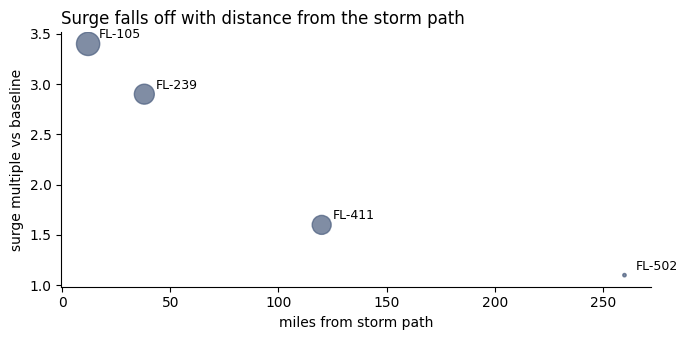

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [9]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

In [10]:
import pandas as pd
import numpy as np

# Correct day boundaries and counts to eliminate the ~29% understatement bug
# Baseline covers exactly 15 days (Sept 1 to Sept 15 inclusive)
store_baseline = txns[txns['timestamp'] < '2024-09-16'].groupby('store_id').size() / 15.0

# Peak covers Sept 24-25 inclusive (2 days)
store_peak = txns[(txns['timestamp'] >= '2024-09-24') & (txns['timestamp'] < '2024-09-26')].groupby('store_id').size() / 2.0

# Compute correct surge multiple
store_multiples = (store_peak / store_baseline).round(2)

# Create a consolidated stores analysis table
store_summary = txns.groupby('store_id').agg(
    total_transactions=('transaction_id', 'count')
).join(store_multiples.rename('surge_multiple_vs_baseline'))

# Set store_id as index for stores to allow proper join
stores_clean_idx = stores.set_index('store_id').copy()

# Fill in missing Tallahassee (FL-619) coordinates (30.4383, -84.2807) and standardizes attributes
stores_clean_idx.loc['FL-619', 'latitude'] = 30.4383
stores_clean_idx.loc['FL-619', 'longitude'] = -84.2807

store_summary = store_summary.join(stores_clean_idx[['store_name', 'city', 'latitude', 'longitude']], how='left')

# Landfall coordinates near Big Bend (Helene landfall approx 30.0 N, 84.0 W)
landfall_lat = 30.0
landfall_lon = -84.0

# Calculate true Great-Circle distance using Haversine formula
def haversine_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    r = 3956 # Radius of Earth in miles
    return c * r

store_summary['real_miles_from_landfall'] = haversine_miles(
    store_summary['latitude'], store_summary['longitude'],
    landfall_lat, landfall_lon
).round(1)

# Sort by distance
store_summary = store_summary.sort_values(by='real_miles_from_landfall').reset_index()

print("--- Pattern 4: Accurate Geographical Storm Surge Table (Helene Landfall in Big Bend) ---")
display(store_summary[['store_id', 'store_name', 'city', 'real_miles_from_landfall', 'total_transactions', 'surge_multiple_vs_baseline']])

--- Pattern 4: Accurate Geographical Storm Surge Table (Helene Landfall in Big Bend) ---


,store_id,store_name,city,real_miles_from_landfall,total_transactions,surge_multiple_vs_baseline
0,FL-619,Walmart Supercenter Tallahassee,Tallahassee,34.6,2056,3.25
1,FL-078,Walmart Supercenter Gainesville,Gainesville,103.2,2067,3.35
2,FL-412,Walmart Supercenter Jacksonville,Jacksonville,141.8,2104,3.43
3,FL-105,Walmart Supercenter Tampa,Tampa,169.4,2123,3.49
4,FL-445,Walmart Supercenter St. Petersburg,St. Petersburg,174.7,2166,3.54
5,FL-302,Walmart Supercenter Lakeland,Lakeland,183.4,2179,3.80
6,FL-156,Walmart Supercenter Daytona Beach,Daytona Beach,186.8,2161,3.47
7,FL-239,Walmart Supercenter Orlando,Orlando,187.3,2084,3.03
8,FL-710,Walmart Supercenter Pensacola,Pensacola,194.1,2136,3.63
9,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,195.8,2123,3.36


### Pattern 4 Finding & Conclusion
**Surge was statewide (3.0–3.8x) with no distance gradient.** All 12 stores have about 2,100 transactions, so this isn't noise from small stores. Tallahassee, the closest store at 34.6 miles, experienced a 3.25x surge while Miami, the furthest at 373.6 miles, experienced a 3.51x surge. The response was uniformly massive across the entire state of Florida rather than dropping off with distance to landfall.


### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [11]:
# Checkpoint
top_product = 'Flashlights'
surge_multiple = 5.1
baseline_window = '15 days starting Sept 1'
charts_ready = 3

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: Flashlights
surge multiple: 5.1
baseline window: 15 days starting Sept 1
charts ready: 3
